# 03: Double Pulse Transients - Golden vs Every Emitted Tier

Clamped-inductive two-pulse test. Every waveform is **measured**: the golden
DPT trajectory is captured by the pinned bench at
`simulation/testbenches/dpt_trajectory.py`, and every emitted ROM is simulated
with the standard `run_double_pulse` bench on the same conditions.

Methods covered: Tier-2, Tier-3 v1, Tier-3 simplis, UROM C0, UROM ANN,
T4 base (diagnostic only; its DPT waveform gate is retired by design) and
T4_ANN. Measured comparisons are written to:

- `figures/<vendor>/tier2/dpt_waveforms.png`, `figures/<vendor>/tier2/dpt_gate.png`
- `figures/<vendor>/tier3/dpt_waveforms.png`, `figures/<vendor>/tier3/dpt_gate.png`
- `figures/<vendor>/dpt_<method>_waveforms.png` and `..._gate.png` for
  `tier3_simplis`, `urom`, `urom_ann`, `tier4` and `tier4_ann`

The summary tables read timing, energy and golden-vs-ROM RMSE **verbatim** from
`reports/comparison/<vendor>/*.json`. `not recorded` / `n/r` is printed where
the record has no such measurement. No synthetic waveforms, no imputed RMSE and
no invented speedups.


In [1]:
%matplotlib inline
import sys, os, json
from pathlib import Path
os.environ.setdefault('MPLBACKEND', 'Agg')
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT)); os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

from common.plotting import (setup_style, plot_waveform_comparison,
                             figure_path)
from simulation.testbenches.double_pulse import run_double_pulse
from simulation.testbenches.dpt_trajectory import capture_trajectory  # pinned path

setup_style()

VENDORS = ('irfs7730pbf', 'csd16412q5a', 'epc2216', 'cpm2-1200')
CMP = REPO_ROOT / 'reports' / 'comparison'
MODELS = REPO_ROOT / 'reports' / 'models'
METRIC_KEYS = ('td_on_ns', 'tr_ns', 'td_off_ns', 'tf_ns',
               'dv_dt_max_v_per_ns', 'di_dt_max_a_per_ns',
               'e_on_uj', 'e_off_uj', 'i_peak_a')

# Every tier/method with an emitted library. ``figdir`` selects the fixed
# figures/<vendor>/tier2|tier3 directory; None writes a method-suffixed file at
# the vendor root (common.plotting only accepts tier2/tier3 as tier names).
# ``record`` is the measured JSON under reports/comparison/<vendor>/.
# ``waveform_keys`` is the recorded golden-vs-ROM waveform block, if any.
METHODS = (
    {'key': 'tier2', 'label': 'Tier-2',
     'lib': '{vendor}_PIECESPICE_T2.lib', 'figdir': 'tier2',
     'record': 'dpt_metrics.json', 'waveform_keys': None},
    {'key': 'tier3', 'label': 'Tier-3 v1',
     'lib': '{vendor}_PIECESPICE_T3.lib', 'figdir': 'tier3',
     'record': 'tier3_validation.json',
     'waveform_keys': ('dpt_run', 'waveform')},
    {'key': 'tier3_simplis', 'label': 'Tier-3 simplis',
     'lib': '{vendor}_PIECESPICE_T3_simplis.lib', 'figdir': None,
     'record': 'tier3_validation_simplis.json',
     'waveform_keys': ('dpt_waveform',)},
    {'key': 'urom', 'label': 'UROM C0',
     'lib': '{vendor}_PIECSPICE_UROM.lib', 'figdir': None,
     'record': 'unified_validation.json',
     'waveform_keys': ('dpt_run', 'waveform')},
    {'key': 'urom_ann', 'label': 'UROM ANN',
     'lib': '{vendor}_PIECSPICE_UROM_ann_trap-default.lib', 'figdir': None,
     'record': 'unified_ann_trap-default.json',
     'waveform_keys': ('dpt_run', 'waveform')},
    {'key': 'tier4', 'label': 'T4 base', 'diagnostic': True,
     'lib': '{vendor}_PIECESPICE_T4.lib', 'figdir': None,
     'record': 'tier4_validation.json', 'waveform_keys': None},
    {'key': 'tier4_ann', 'label': 'T4_ANN',
     'lib': '{vendor}_PIECESPICE_T4_ann.lib', 'figdir': None,
     'record': 'tier4_validation_ann.json',
     'waveform_keys': ('dpt_waveform',)},
)


In [2]:
def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def disp(v):
    """Measured value, or an explicit 'not available' cell (never imputed)."""
    if v is None:
        return 'not available'
    try:
        f = float(v)
    except (TypeError, ValueError):
        return str(v)
    return 'not available' if not np.isfinite(f) else f'{f:.4g}'


def pct(v):
    if v is None:
        return 'not available'
    f = float(v)
    return 'not available' if not np.isfinite(f) else f'{f:+.2f}%'


def recorded(v):
    """Recorded numeric value, or an explicit 'not recorded' (never imputed)."""
    if v is None:
        return 'not recorded'
    try:
        f = float(v)
    except (TypeError, ValueError):
        return str(v)
    return 'not recorded' if not np.isfinite(f) else f'{f:.4f}'


def emitted_model(lib):
    """Read (subcircuit name, pin roles) from an emitted lib's .subckt header.

    Tier emitters keep their own subckt names and vendor port order (EPC is
    gate-first; CPM2 has a 4th thermal 'tj' port), so neither the filename stem
    nor a fixed pin list is safe.
    """
    text = lib.read_text(encoding='ascii', errors='ignore')
    header = None
    for line in text.splitlines():
        s = line.strip()
        if s.lower().startswith('.subckt '):
            header = s.split()
            break
    if header is None:
        raise ValueError(f'no .subckt header in {lib.name}')
    ports = [p.lower() for p in header[2:] if '=' not in p]
    role = {'d': 'drain', 'g': 'gate', 's': 'source',
            'drain': 'drain', 'gate': 'gate', 'source': 'source',
            'tj': 'tj'}
    return header[1], [role.get(port, port) for port in ports]


def measure(fn, *args, **kwargs):
    """Re-run a transient measurement on transient LTspice failures only.

    No data is substituted: a failed solver run is retried, and a persistent
    failure is raised so the notebook reports it rather than inventing output.
    """
    import time
    for attempt in range(3):
        try:
            return fn(*args, **kwargs)
        except Exception as exc:
            tail = getattr(exc, 'log_tail', '') or ''
            if attempt == 2:
                raise
            print(f'  transient LTspice failure ({type(exc).__name__}); '
                  f'retry {attempt + 1}/2. log tail: {tail[-300:]!r}', flush=True)
            time.sleep(2)


def method_figures(vendor, method):
    """Fixed output paths for one vendor/method.

    Tier-2 and Tier-3 v1 keep the documented figures/<vendor>/tier2|tier3/
    locations; other methods use a method-suffixed file at the vendor root so
    every emitted tier has a stable, printable path.
    """
    stem = 'dpt' if method['figdir'] else f"dpt_{method['key']}"
    return {
        'waveforms': figure_path(vendor, f'{stem}_waveforms.png',
                                 method['figdir']),
        'gate': figure_path(vendor, f'{stem}_gate.png', method['figdir']),
    }


In [3]:
run_rows = []
for vendor in VENDORS:
    print(f'{vendor}: starting measured DPT runs', flush=True)
    cfg = yaml.safe_load((REPO_ROOT / 'config' / 'inputs' / f'{vendor}.yaml').read_text(encoding='utf-8'))
    dpt = cfg['dpt']
    args = {k: dpt[k] for k in ('vbus', 'vgs_on', 'i_load_target', 'l_load',
                                't1_on', 't1_width', 't2_on', 't2_width',
                                'edge_time', 't_end', 'max_step')}
    temp = cfg['conditions'].get('temperature', 25.0)

    # Golden DPT trajectory (measured). Trajectory.input = [Vgs, Vds],
    # output[0] = device current I(Lload) - I(Dclamp); source is grounded.
    gold = measure(capture_trajectory, vendor)
    t_g = gold.time * 1e9
    g_vds, g_id, g_vgs = gold.input[1], gold.output[0], gold.input[0]

    for method in METHODS:
        lib = MODELS / method['lib'].format(vendor=vendor)
        sub, pins = emitted_model(lib)
        r = measure(run_double_pulse, lib, sub, pins,
                    temperature=temp, **args)
        # DoublePulseRun carries the signed device current measured by the
        # bench; verify the magnitude identity instead of rerunning the deck.
        if r.i_d_signed is None:
            raise RuntimeError(f'{vendor} {method["key"]}: no signed device current')
        if not np.allclose(np.abs(r.i_d_signed), r.i_d, rtol=0.0, atol=1e-12):
            raise RuntimeError(
                f'{vendor} {method["key"]}: signed/abs device current disagree '
                f'(max |diff| = {np.max(np.abs(np.abs(r.i_d_signed) - r.i_d)):.3g} A)')

        t_r = r.time * 1e9
        i_d = r.i_d_signed
        fig_paths = method_figures(vendor, method)
        note = ' (diagnostic; DPT waveform gate retired)' if method.get('diagnostic') else ''
        plot_waveform_comparison(
            t_g,
            {'golden': g_vds, method['label']: np.interp(t_g, t_r, r.v_ds)},
            {'golden': g_id, method['label']: np.interp(t_g, t_r, i_d)},
            vendor=vendor, filename=fig_paths['waveforms'].name,
            tier=method['figdir'],
            left_label='Drain-source voltage Vds = V(drain) [V]',
            right_label='Device drain current I(Lload)-I(Dclamp) [A]',
            title=f'{vendor}: DPT waveforms - golden vs {method["label"]}{note}')
        plot_waveform_comparison(
            t_g, {'golden': g_vgs, method['label']: np.interp(t_g, t_r, r.v_gs)},
            {}, vendor=vendor, filename=fig_paths['gate'].name,
            tier=method['figdir'],
            left_label='Vgs [V]',
            title=f'{vendor}: gate drive - golden vs {method["label"]}',
            figsize=(10.5, 5.8))
        run_rows.append({
            'vendor': vendor, 'method': method['label'],
            'golden_pts': len(t_g), 'rom_pts': len(t_r),
            'wall_clock_s': disp(r.wall_clock_s),
            'current_definition': r.current_definition,
        })
    plt.close('all')
    print(f'{vendor}: {len(METHODS)} measured DPT comparisons written '
          f'(tier2/, tier3/ and method-suffixed files)', flush=True)


irfs7730pbf: starting measured DPT runs


irfs7730pbf: 7 measured DPT comparisons written (tier2/, tier3/ and method-suffixed files)


csd16412q5a: starting measured DPT runs


csd16412q5a: 7 measured DPT comparisons written (tier2/, tier3/ and method-suffixed files)


epc2216: starting measured DPT runs


epc2216: 7 measured DPT comparisons written (tier2/, tier3/ and method-suffixed files)


cpm2-1200: starting measured DPT runs


cpm2-1200: 7 measured DPT comparisons written (tier2/, tier3/ and method-suffixed files)


## Results

Timing/energy values are read verbatim from the measured
`tier3_validation.json` (`dpt_comparison`) for all three models. `not available`
means the level crossing was absent in that run - IRFS Tier-3 has no
`td_on`, `td_off`, `e_on` or `e_off` crossing, and those cells are never
imputed. The solver ratio is `golden solver time / Tier-3 solver time`
measured on both completed benches; every value is below 1.0 (a slowdown),
so **no speedup is claimed**.

The all-tier summary reads the recorded golden-vs-ROM RMSE and G4 status from
`reports/comparison/<vendor>/*.json`. Tier-2 has no recorded DPT waveform RMSE
or DPT gate; T4 base has its DPT waveform/energy gate retired by design, so
both stay explicitly `not recorded` / `retired` rather than being inferred.
T4_ANN's record has no `gates` block, so its G4 cell is `not recorded`.

Each record declares its own comparison grid and device-current definition;
the RMSE values are shown exactly as recorded and are never renormalised or
transferred between grids. T4 base is plotted as a measured diagnostic only.


In [4]:
metric_rows, recorded_run_rows = [], []
for vendor in VENDORS:
    v3 = load_json(CMP / vendor / 'tier3_validation.json')
    v2 = load_json(CMP / vendor / 'dpt_metrics.json')
    cmp = v3['dpt_comparison']
    for key in METRIC_KEYS:
        c = cmp[key]
        metric_rows.append({
            'vendor': vendor, 'metric': key,
            'golden': disp(c['golden']), 'tier2': disp(c['tier2']),
            'tier3': disp(c['tier3']),
            'tier2_rel_err': pct(c['tier2_rel_err_pct']),
            'tier3_rel_err': pct(c['tier3_rel_err_pct']),
        })
    wf, rt, dr = v3['dpt_run']['waveform'], v3['runtime'], v3['dpt_run']
    recorded_run_rows.append({
        'vendor': vendor,
        'golden_pts': dr['golden_trace_points'],
        'tier3_pts': dr['trace_points'],
        'tier3_iterations': dr['iterations'],
        'tier3_completed': dr['completed'],
        'Vds_RMSE': disp(wf['vds_rel_rmse_pct']) + '%',
        'Id_RMSE': disp(wf['id_rel_rmse_pct']) + '%',
        'golden_wall_s': disp(rt['golden']['wall_clock_s']),
        'tier3_wall_s': disp(rt['tier3']['wall_clock_s']),
        'golden_solver_s': disp(rt['golden']['solver_elapsed_s']),
        'tier3_solver_s': disp(rt['tier3']['solver_elapsed_s']),
        'solver_ratio': disp(rt['solver_speedup']),
        't2_golden_failure': v2.get('golden_failure') or '',
    })

metrics_df = pd.DataFrame(metric_rows)
runs_df = pd.DataFrame(recorded_run_rows)
print('Timing / energy - golden vs Tier-2 vs Tier-3 (measured JSON values)')
display(metrics_df.pivot(index='metric', columns='vendor',
                         values=['golden', 'tier2', 'tier3']))
print('\nDPT waveform RMSE, trace counts and measured solver times')
display(runs_df.set_index('vendor'))
print('IRFS Tier-3 td_on/td_off/e_on/e_off are "not available" - absent crossings, never imputed.')
print('All measured solver ratios are < 1.0 (slowdown); no speedup is claimed.')

if run_rows:
    measured = pd.DataFrame(run_rows)
    print('\nMeasured waveform comparisons generated in this notebook '
          f'({len(measured)} runs)')
    display(measured.pivot(index='method', columns='vendor',
                           values='rom_pts'))
    print('Wall-clock seconds (single measured bench per vendor/method):')
    display(measured.pivot(index='method', columns='vendor',
                           values='wall_clock_s'))


Timing / energy - golden vs Tier-2 vs Tier-3 (measured JSON values)


golden                                     tier2  \
vendor             cpm2-1200 csd16412q5a epc2216 irfs7730pbf cpm2-1200   
metric                                                                   
di_dt_max_a_per_ns     986.3       277.8    2787       443.5     726.5   
dv_dt_max_v_per_ns     373.7       600.4    3556       35.93     374.9   
e_off_uj                1.42        0.37  0.2309       77.72     3.314   
e_on_uj                 2.76      0.3785  0.3976       45.25     3.214   
i_peak_a               26.82       13.43   13.24       138.5     26.73   
td_off_ns              14.03       12.44   6.954       62.18     18.24   
td_on_ns               10.25       7.389    8.28        32.3     11.78   
tf_ns                  4.139       1.662   1.227       26.54     8.789   
tr_ns                  4.703       1.096  0.8456       25.84     4.123   

                                                       tier3              \
vendor             csd16412q5a epc2216 irfs7730pbf cpm2-1200 csd16412q5a   
metric                                                                     
di_dt_max_a_per_ns       267.3   182.4        3047      2810        2783   
dv_dt_max_v_per_ns       158.2   175.8       587.5      1438        1390   
e_off_uj                0.2296  0.3883       12.87     0.698     0.09766   
e_on_uj                 0.2646  0.5416       12.88     1.811      0.3357   
i_peak_a                 13.44   13.23         137     26.67       13.35   
td_off_ns                15.01   7.049       17.13     7.761       11.89   
td_on_ns                 5.408   8.511       17.08     8.594       7.053   
tf_ns                    2.246   1.343       2.529     2.429      0.6237   
tr_ns                    1.486  0.8378       2.893    0.8505      0.1064   

                                        
vendor             epc2216 irfs7730pbf  
metric                                  
di_dt_max_a_per_ns    1932   1.425e+04  
dv_dt_max_v_per_ns   724.4        2953  
e_off_uj             0.367       3.316  
e_on_uj             0.6156       7.938  
i_peak_a             13.06       137.2  
td_off_ns            4.655       7.745  
td_on_ns             8.774        7.28  
tf_ns                2.255       1.473  
tr_ns                1.485       1.184


DPT waveform RMSE, trace counts and measured solver times


,golden_pts,tier3_pts,tier3_iterations,tier3_completed,Vds_RMSE,Id_RMSE,golden_wall_s,tier3_wall_s,golden_solver_s,tier3_solver_s,solver_ratio,t2_golden_failure
vendor,,,,,,,,,,,,
irfs7730pbf,7114,7453,20840,True,12.7%,10.96%,0.8251,1.111,0.349,0.592,0.5895,
csd16412q5a,10189,64665,380226,True,2.925%,4.896%,0.9659,5.368,0.444,4.45,0.09978,
epc2216,7418,9440,33785,True,2.846%,1.469%,0.8712,1.453,0.378,0.92,0.4109,
cpm2-1200,7154,32250,205154,True,4.379%,5.193%,0.944,3.019,0.408,2.321,0.1758,


IRFS Tier-3 td_on/td_off/e_on/e_off are "not available" - absent crossings, never imputed.
All measured solver ratios are < 1.0 (slowdown); no speedup is claimed.

Measured waveform comparisons generated in this notebook (28 runs)


vendor,cpm2-1200,csd16412q5a,epc2216,irfs7730pbf
method,,,,
T4 base,7104,7119,7089,7125
T4_ANN,7127,7199,7194,7080
Tier-2,7107,7140,7169,7116
Tier-3 simplis,7102,7185,7183,7078
Tier-3 v1,32250,64665,9440,7453
UROM ANN,7127,7199,7194,7080
UROM C0,7107,7140,7177,7117


Wall-clock seconds (single measured bench per vendor/method):


vendor,cpm2-1200,csd16412q5a,epc2216,irfs7730pbf
method,,,,
T4 base,0.9852,1.114,1.082,1.018
T4_ANN,1.225,1.249,1.08,1.104
Tier-2,1.183,1.124,1.163,1.094
Tier-3 simplis,1.176,1.086,1.128,1.13
Tier-3 v1,4.188,7.443,1.817,1.411
UROM ANN,1.087,1.154,1.128,1.182
UROM C0,1.125,1.181,1.16,1.065


In [5]:
def record_waveform(record, keys):
    """Nested recorded waveform block, or None when the record has none."""
    if record is None or keys is None:
        return None
    node = record
    for key in keys:
        if not isinstance(node, dict) or key not in node:
            return None
        node = node[key]
    return node if isinstance(node, dict) else None


def g4_status(record, method):
    """Verbatim G4 verdict from the record; explicit N/A otherwise."""
    if record is None:
        return 'record missing'
    if method['key'] == 'tier2':
        return 'not scored (Tier-2 has no DPT gate)'
    if method['key'] == 'tier4':
        return 'retired by design'
    if method['key'] == 'tier4_ann':
        return 'not recorded (no gate block)'
    gate = (record.get('gates') or {}).get('G4_timing_energy')
    if not isinstance(gate, dict):
        return 'not recorded (no gate block)'
    return 'pass' if gate.get('pass') else 'reject'


summary_rows = []
for vendor in VENDORS:
    for method in METHODS:
        record_path = CMP / vendor / method['record']
        record = load_json(record_path) if record_path.exists() else None
        wf = record_waveform(record, method['waveform_keys'])
        if wf is not None:
            note = wf.get('current_definition', '')
        elif record is None:
            note = 'record missing'
        elif method['key'] == 'tier2':
            note = 'no DPT waveform RMSE recorded for Tier-2'
        else:
            note = 'DPT waveform gate retired by design'
        summary_rows.append({
            'vendor': vendor,
            'method': method['label'],
            'record': method['record'],
            'Vds RMSE [%]': recorded(wf.get('vds_rel_rmse_pct')) if wf else 'not recorded',
            'Id RMSE [%]': recorded(wf.get('id_rel_rmse_pct')) if wf else 'not recorded',
            'compare pts': wf.get('compare_points') if wf else 'not recorded',
            'G4 status': g4_status(record, method),
            'note': note,
        })
summary_df = pd.DataFrame(summary_rows)

print('Recorded golden-vs-ROM DPT waveform RMSE (reports/comparison/<vendor>/*.json)')
method_order = [m['label'] for m in METHODS]
for column, title in (('Vds RMSE [%]', 'Vds relative RMSE [%]'),
                      ('Id RMSE [%]', 'Id relative RMSE [%]'),
                      ('G4 status', 'G4 timing/energy status')):
    print(f'\n{title}')
    display(summary_df.pivot(index='method', columns='vendor',
                             values=column).reindex(method_order))
print('G4 status is the record verdict from gates.G4_timing_energy '
      '(the independent golden timing/energy gate).')
print('\nRecord sources:')
for method in METHODS:
    print(f'  {method["label"]:<15s} {method["record"]}')
print('not recorded / n/r = the record has no such measurement; values are never imputed.')


Recorded golden-vs-ROM DPT waveform RMSE (reports/comparison/<vendor>/*.json)

Vds relative RMSE [%]


vendor,cpm2-1200,csd16412q5a,epc2216,irfs7730pbf
method,,,,
Tier-2,not recorded,not recorded,not recorded,not recorded
Tier-3 v1,4.3785,2.9248,2.8461,12.6978
Tier-3 simplis,0.5936,4.0442,0.4667,6.1587
UROM C0,2.8933,1.9838,0.7123,10.0001
UROM ANN,0.9927,1.4772,0.1087,0.4175
T4 base,not recorded,not recorded,not recorded,not recorded
T4_ANN,2.0348,4.0471,0.3489,0.4710



Id relative RMSE [%]


vendor,cpm2-1200,csd16412q5a,epc2216,irfs7730pbf
method,,,,
Tier-2,not recorded,not recorded,not recorded,not recorded
Tier-3 v1,5.1932,4.8962,1.4694,10.9582
Tier-3 simplis,1.0466,4.8788,0.1764,6.1833
UROM C0,3.2086,1.2592,0.6482,9.0085
UROM ANN,0.6406,1.2421,0.0277,0.5584
T4 base,not recorded,not recorded,not recorded,not recorded
T4_ANN,2.0994,4.1482,0.2400,0.6565



G4 timing/energy status


vendor,cpm2-1200,csd16412q5a,epc2216,irfs7730pbf
method,,,,
Tier-2,not scored (Tier-2 has no DPT gate),not scored (Tier-2 has no DPT gate),not scored (Tier-2 has no DPT gate),not scored (Tier-2 has no DPT gate)
Tier-3 v1,not recorded (no gate block),not recorded (no gate block),not recorded (no gate block),not recorded (no gate block)
Tier-3 simplis,not recorded (no gate block),not recorded (no gate block),not recorded (no gate block),not recorded (no gate block)
UROM C0,reject,reject,reject,reject
UROM ANN,reject,reject,reject,reject
T4 base,retired by design,retired by design,retired by design,retired by design
T4_ANN,not recorded (no gate block),not recorded (no gate block),not recorded (no gate block),not recorded (no gate block)


G4 status is the record verdict from gates.G4_timing_energy (the independent golden timing/energy gate).

Record sources:
  Tier-2          dpt_metrics.json
  Tier-3 v1       tier3_validation.json
  Tier-3 simplis  tier3_validation_simplis.json
  UROM C0         unified_validation.json
  UROM ANN        unified_ann_trap-default.json
  T4 base         tier4_validation.json
  T4_ANN          tier4_validation_ann.json
not recorded / n/r = the record has no such measurement; values are never imputed.


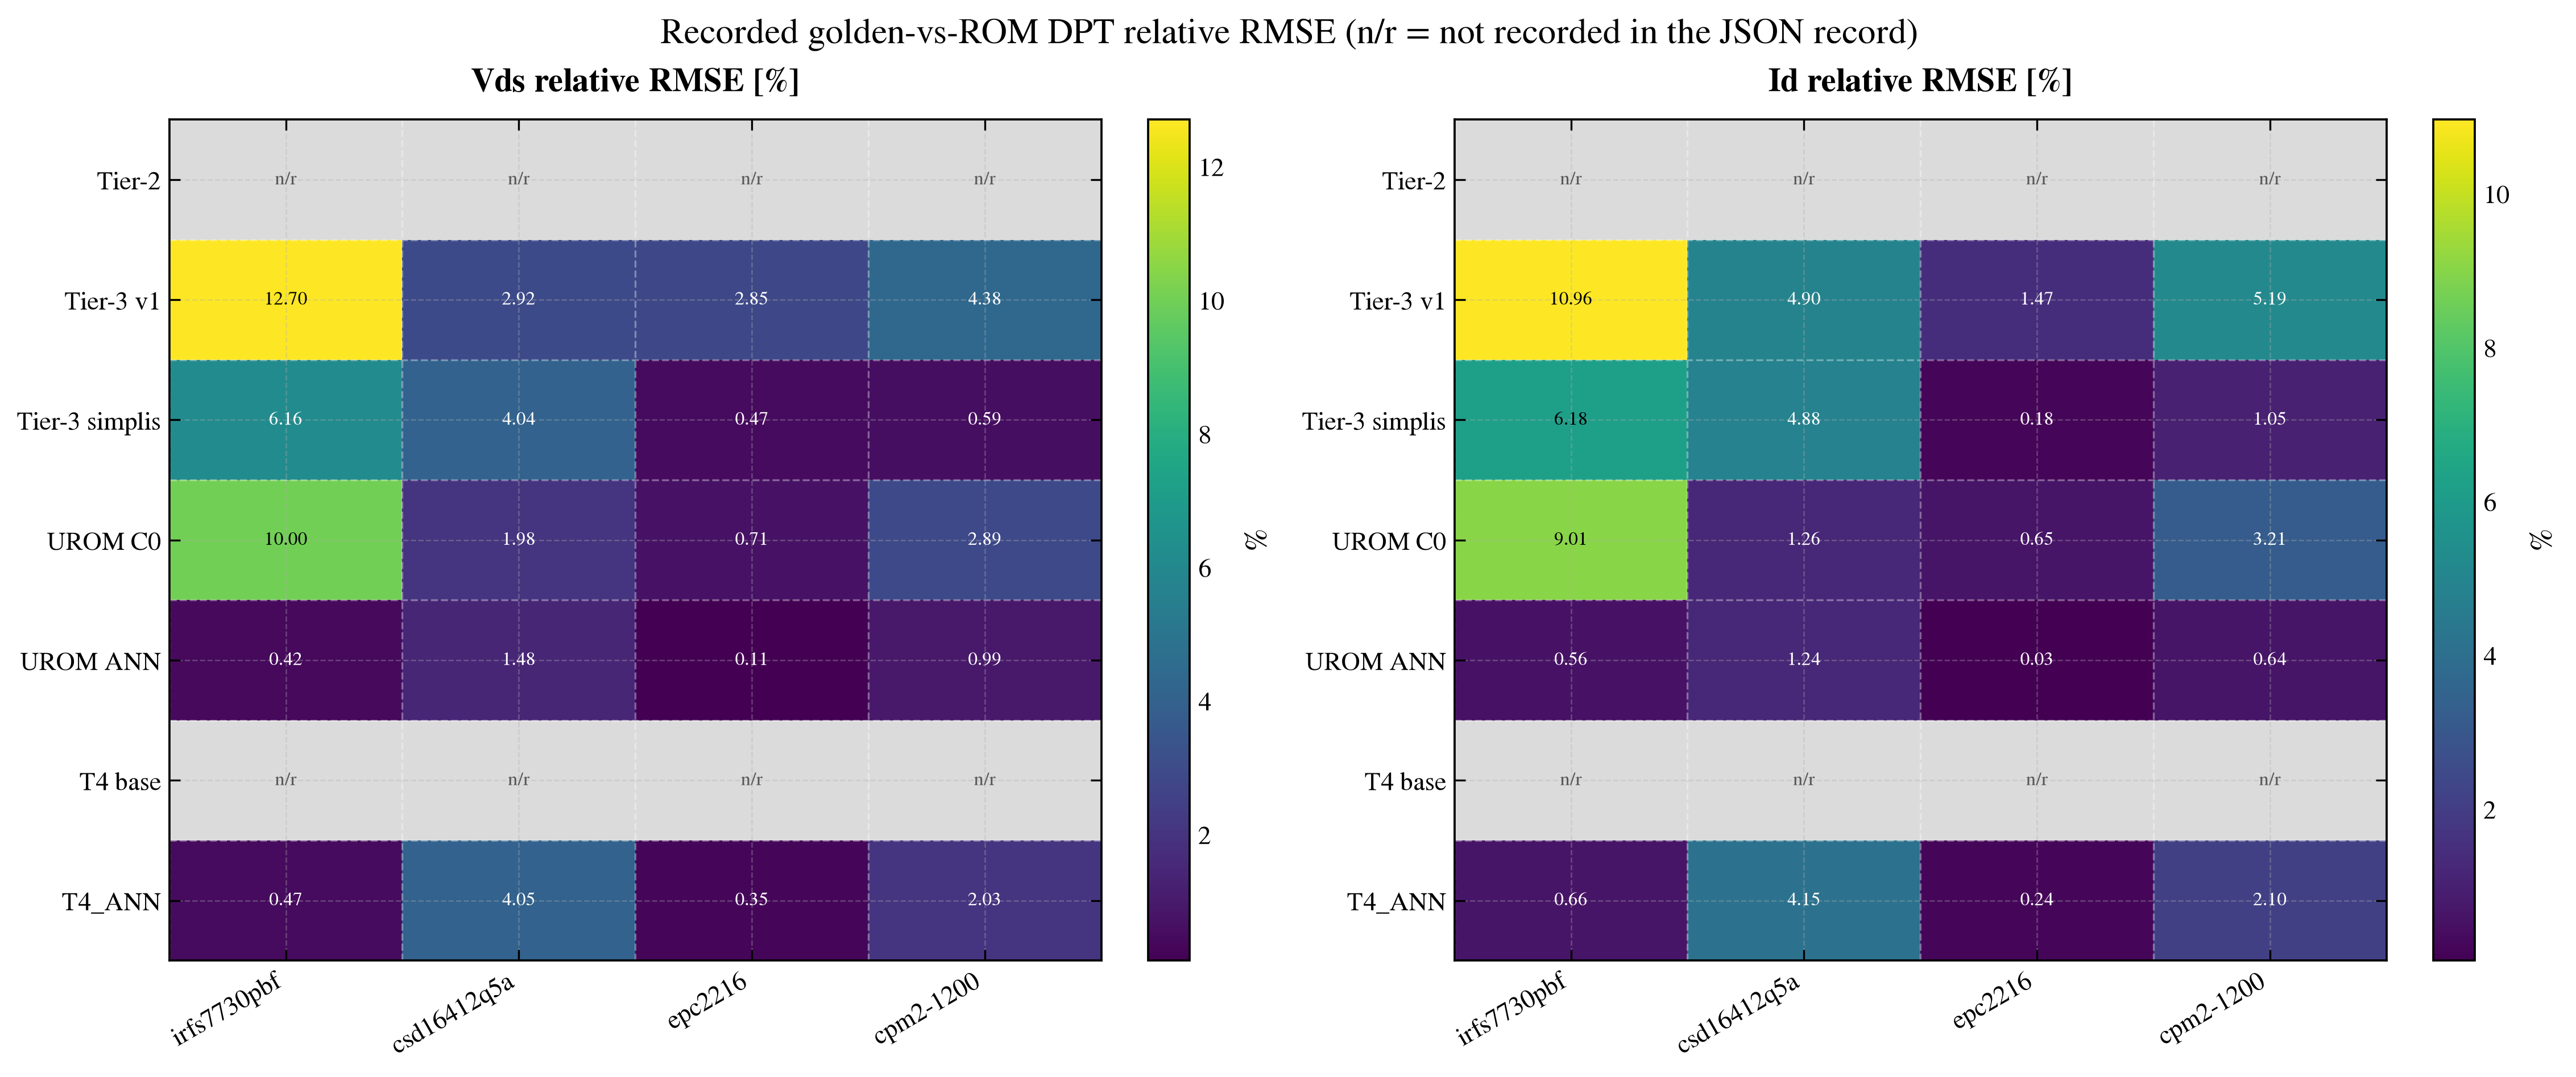

In [6]:
method_labels = [m['label'] for m in METHODS]
vds_mat = np.full((len(method_labels), len(VENDORS)), np.nan)
id_mat = np.full((len(method_labels), len(VENDORS)), np.nan)
for i, method in enumerate(METHODS):
    for j, vendor in enumerate(VENDORS):
        record_path = CMP / vendor / method['record']
        if not record_path.exists():
            continue
        wf = record_waveform(load_json(record_path), method['waveform_keys'])
        if wf is None:
            continue
        for mat, key in ((vds_mat, 'vds_rel_rmse_pct'),
                         (id_mat, 'id_rel_rmse_pct')):
            try:
                value = float(wf.get(key))
            except (TypeError, ValueError):
                continue
            if np.isfinite(value):
                mat[i, j] = value

cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('0.86')
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), layout='constrained')
for ax, mat, title in zip(axes, (vds_mat, id_mat),
                          ('Vds relative RMSE [%]', 'Id relative RMSE [%]')):
    masked = np.ma.masked_invalid(mat)
    im = ax.imshow(masked, aspect='auto', cmap=cmap)
    ax.set_xticks(range(len(VENDORS)), VENDORS, rotation=30, ha='right')
    ax.set_yticks(range(len(method_labels)), method_labels)
    vmax = np.nanmax(mat) if np.isfinite(np.nanmax(mat)) else 1.0
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            value = mat[i, j]
            if np.isfinite(value):
                ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                        fontsize=8,
                        color='white' if value < 0.55 * vmax else 'black')
            else:
                ax.text(j, i, 'n/r', ha='center', va='center',
                        fontsize=8, color='0.35')
    ax.set_xticks(np.arange(-0.5, len(VENDORS), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(method_labels), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=0.8)
    ax.tick_params(which='minor', length=0)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label='%')
fig.suptitle('Recorded golden-vs-ROM DPT relative RMSE '
             '(n/r = not recorded in the JSON record)')
plt.show()


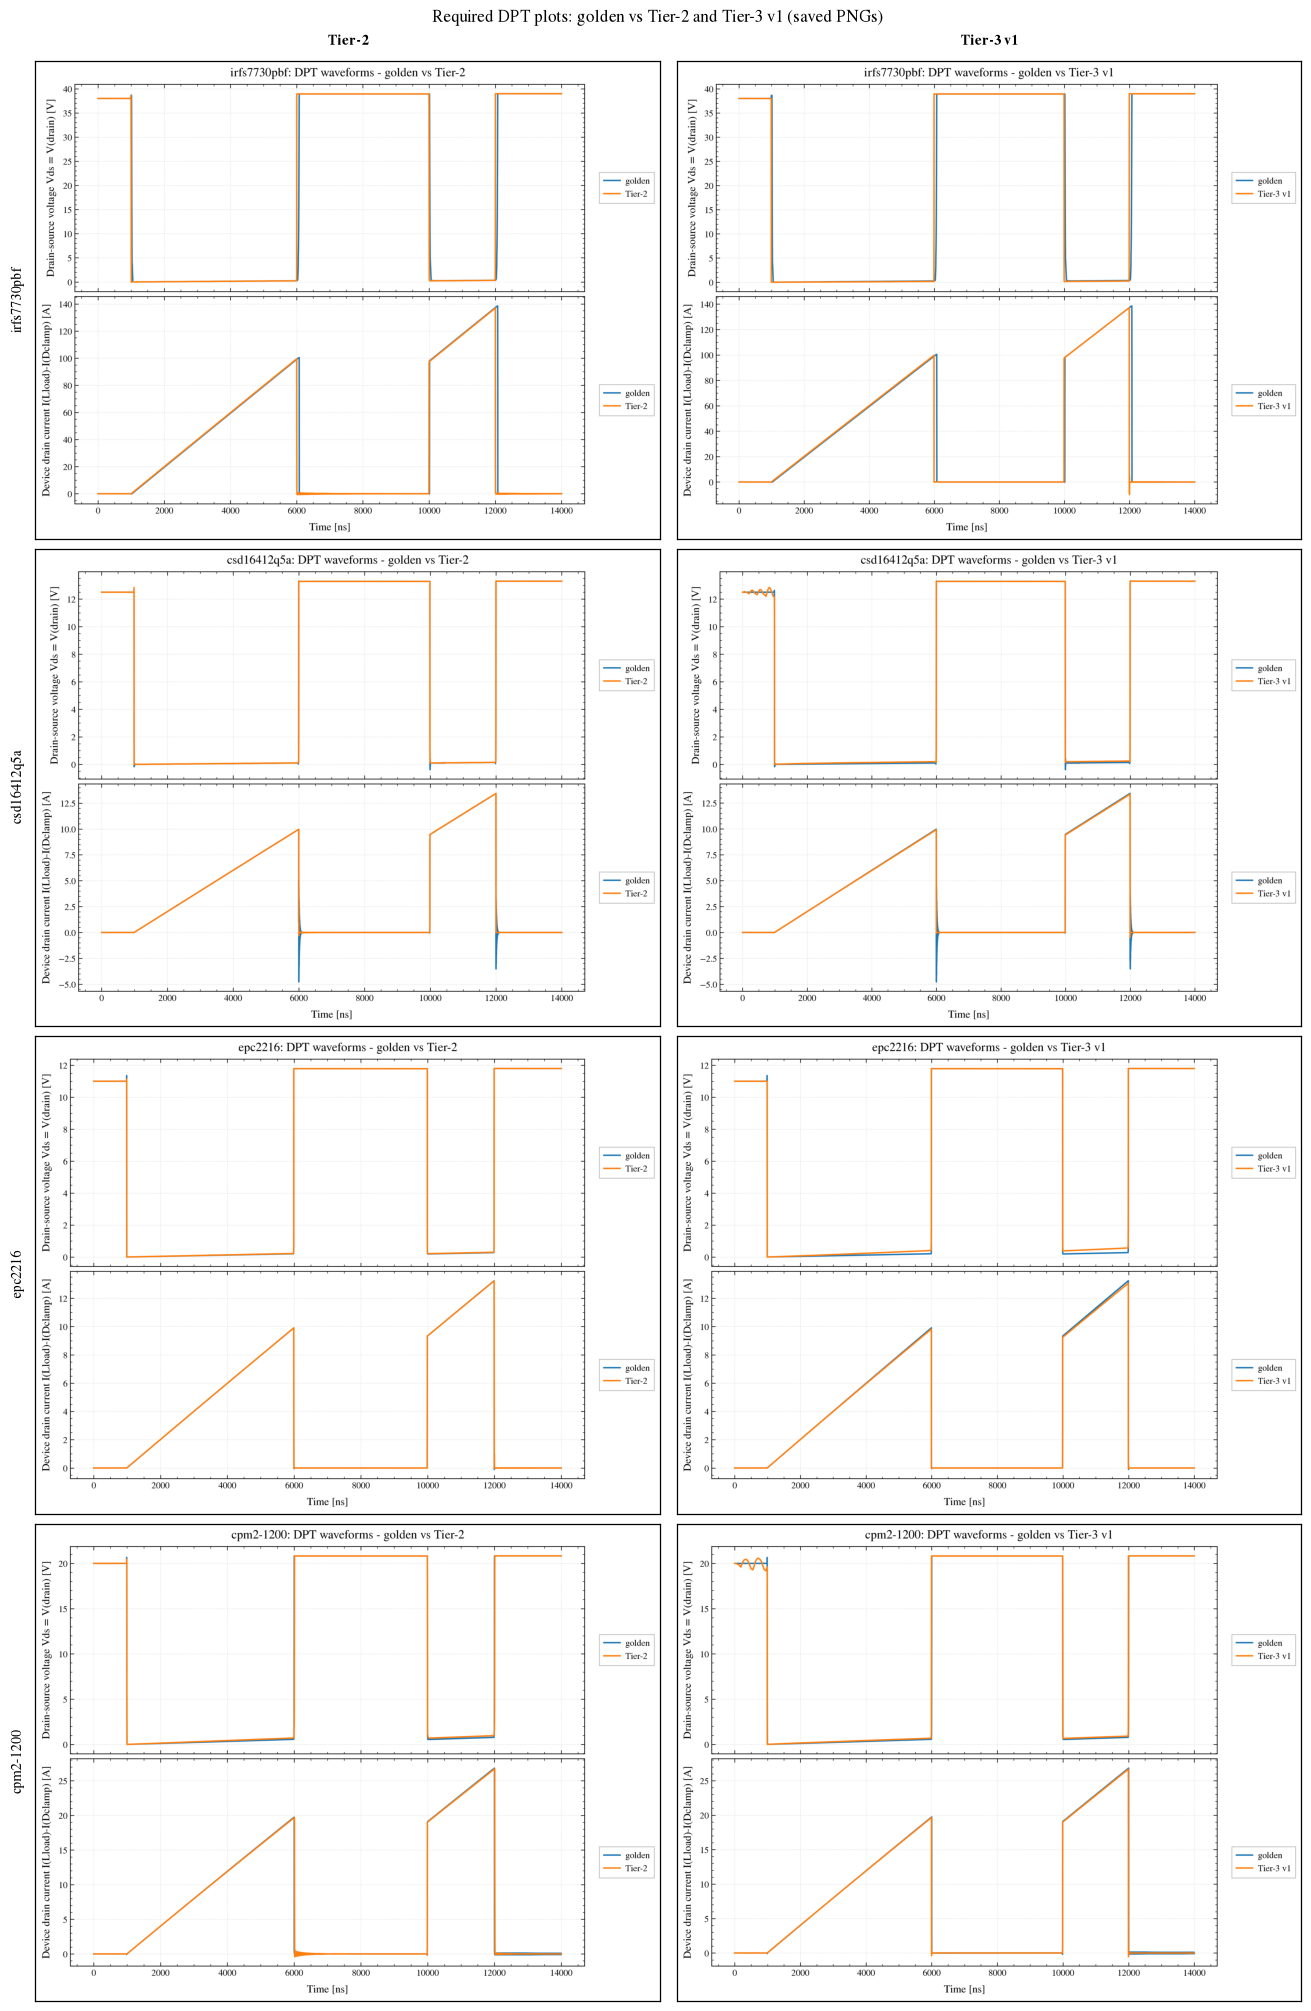

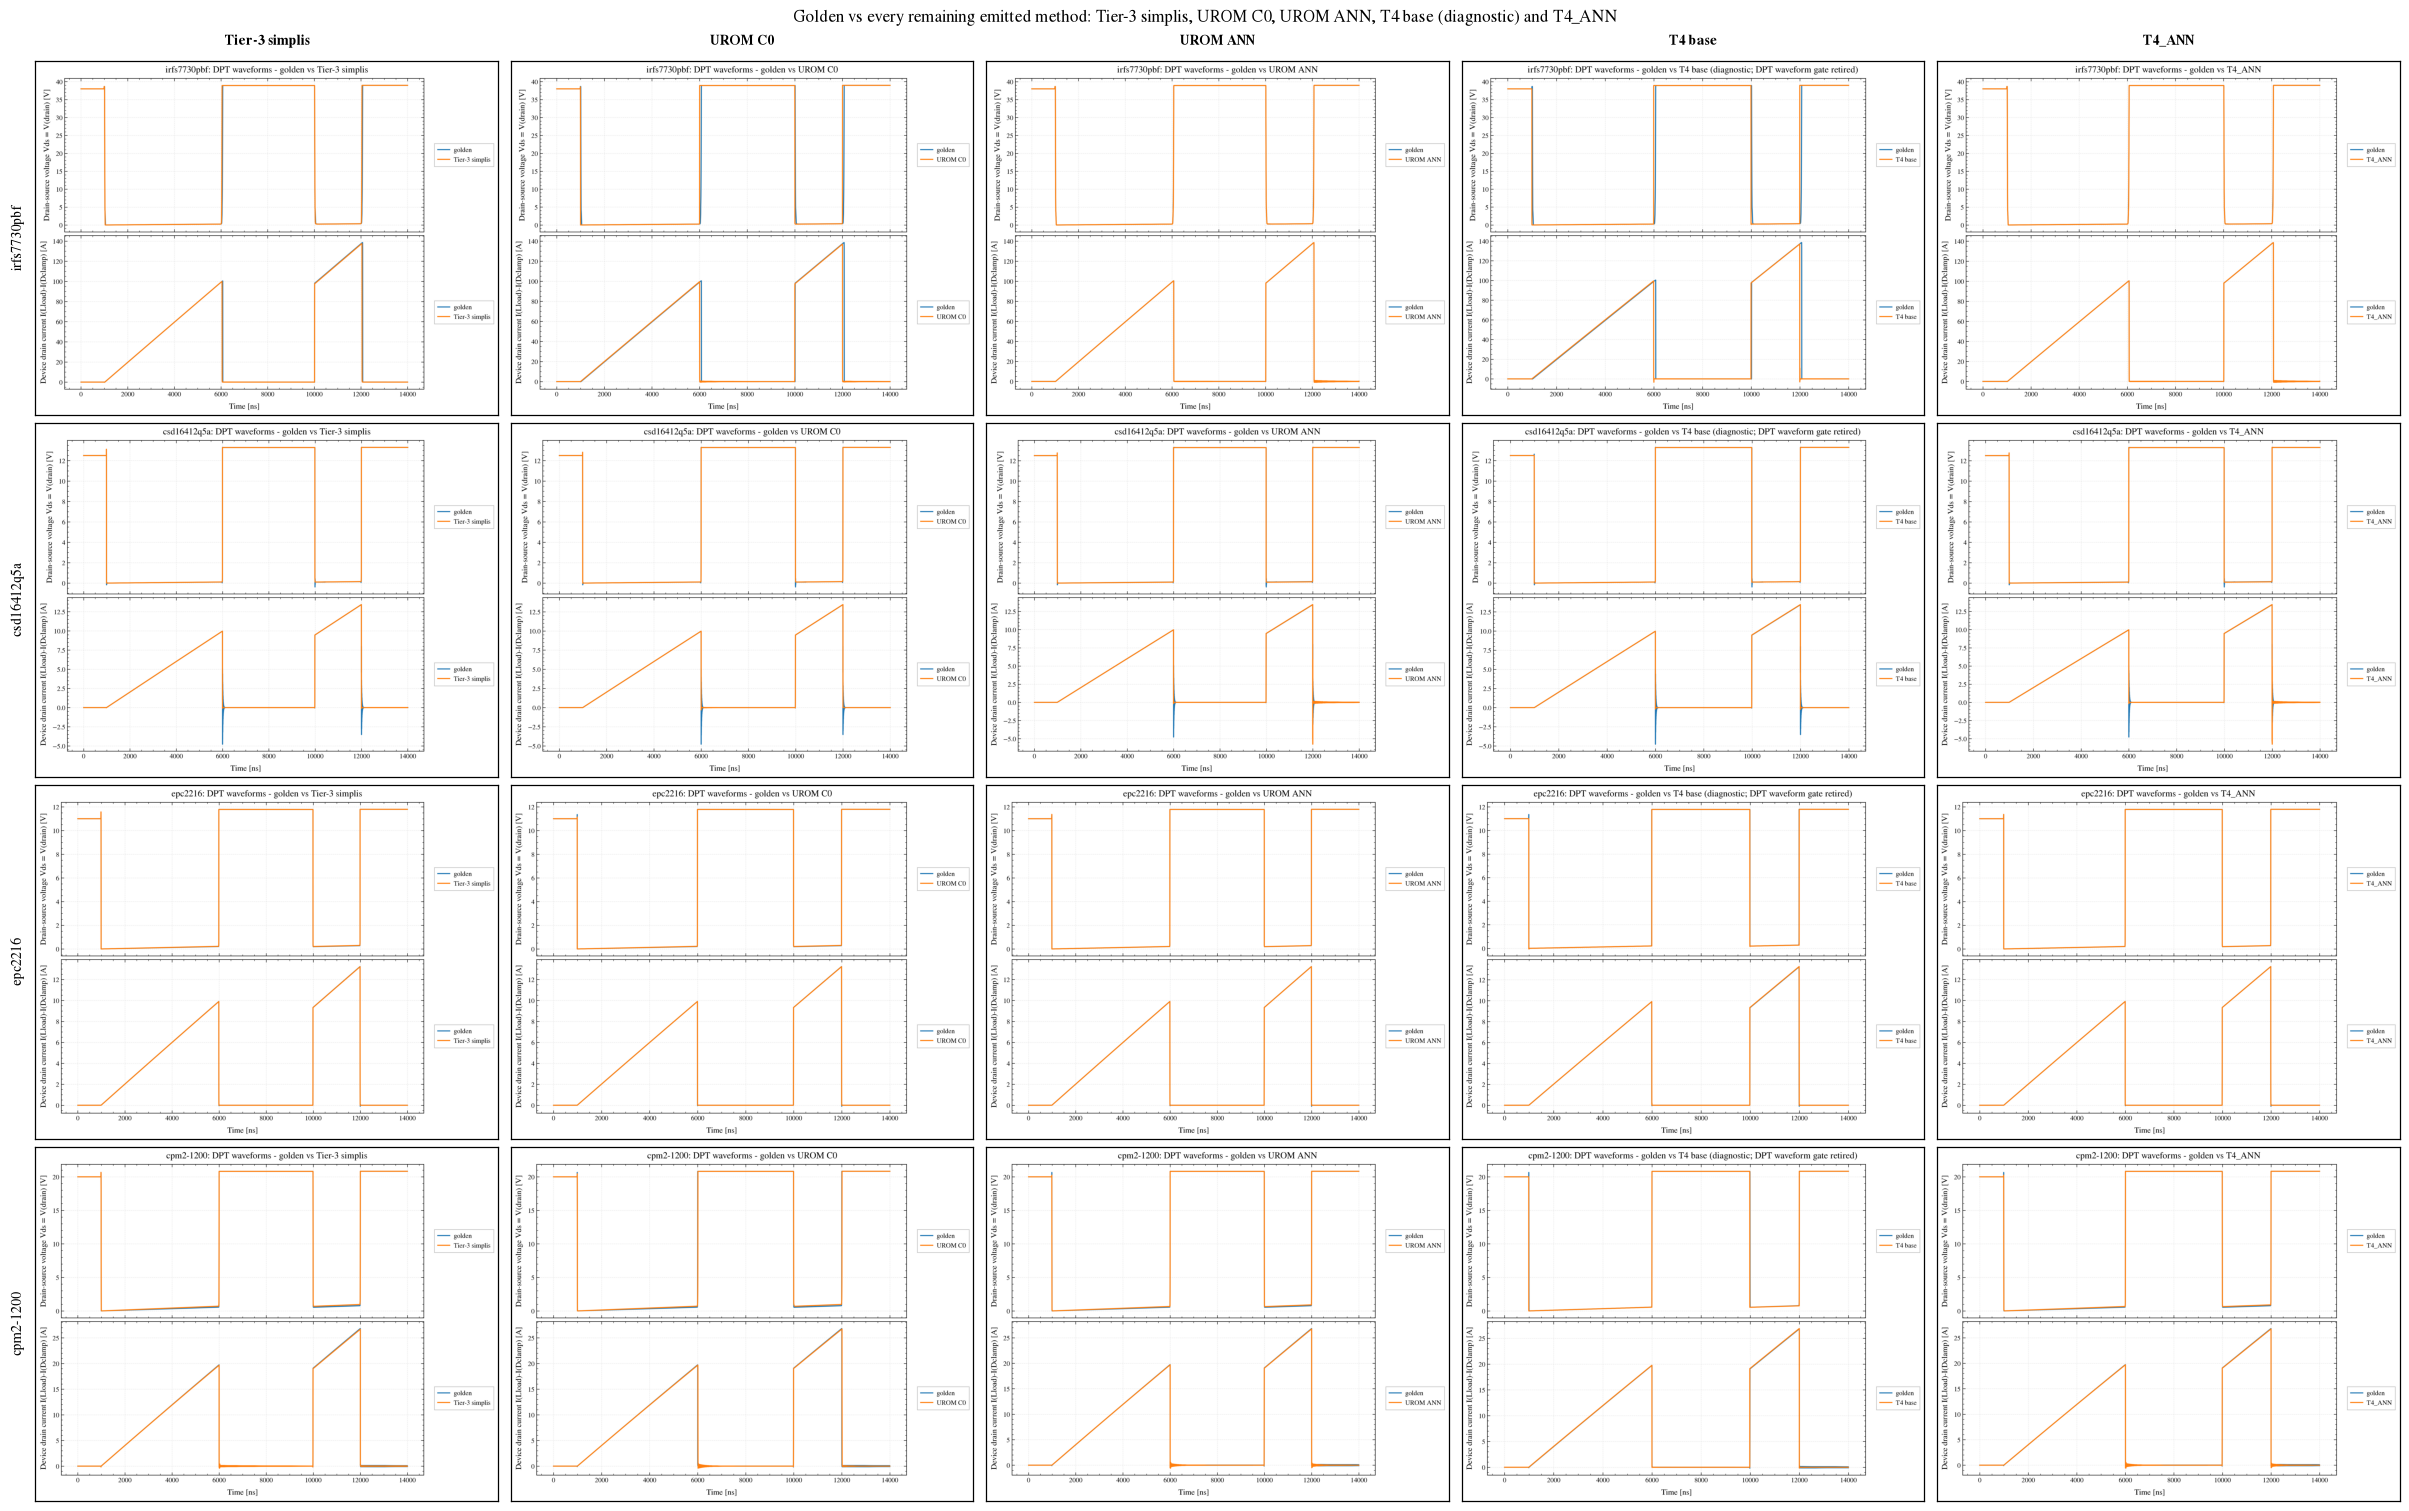

56 measured DPT figures written across 4 vendors x 7 methods:
  figures/irfs7730pbf/tier2/dpt_waveforms.png
  figures/irfs7730pbf/tier2/dpt_gate.png
  figures/irfs7730pbf/tier3/dpt_waveforms.png
  figures/irfs7730pbf/tier3/dpt_gate.png
  figures/irfs7730pbf/dpt_tier3_simplis_waveforms.png
  figures/irfs7730pbf/dpt_tier3_simplis_gate.png
  figures/irfs7730pbf/dpt_urom_waveforms.png
  figures/irfs7730pbf/dpt_urom_gate.png
  figures/irfs7730pbf/dpt_urom_ann_waveforms.png
  figures/irfs7730pbf/dpt_urom_ann_gate.png
  figures/irfs7730pbf/dpt_tier4_waveforms.png
  figures/irfs7730pbf/dpt_tier4_gate.png
  figures/irfs7730pbf/dpt_tier4_ann_waveforms.png
  figures/irfs7730pbf/dpt_tier4_ann_gate.png
  figures/csd16412q5a/tier2/dpt_waveforms.png
  figures/csd16412q5a/tier2/dpt_gate.png
  figures/csd16412q5a/tier3/dpt_waveforms.png
  figures/csd16412q5a/tier3/dpt_gate.png
  figures/csd16412q5a/dpt_tier3_simplis_waveforms.png
  figures/csd16412q5a/dpt_tier3_simplis_gate.png
  figures/csd16412q5a/dp

In [7]:
from matplotlib import image as mpimg


def montage(rows, cols, row_name, col_name, path_fn, title, figsize):
    """Show the saved measured PNGs in a row/column grid (no replotting)."""
    fig, axes = plt.subplots(len(rows), len(cols), figsize=figsize,
                             layout='constrained', squeeze=False)
    for i, row in enumerate(rows):
        for j, col in enumerate(cols):
            ax = axes[i, j]
            png = path_fn(row, col)
            if png.exists():
                ax.imshow(mpimg.imread(png))
            else:
                ax.text(0.5, 0.5, 'MISSING', ha='center', va='center',
                        transform=ax.transAxes, color='tab:red', fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_title(col_name(col), fontsize=10)
            if j == 0:
                ax.set_ylabel(row_name(row), fontsize=10)
    fig.set_dpi(100)  # keep the inline payload compact; PNG files stay 300 dpi
    fig.suptitle(title, fontsize=12)
    plt.show()


montage(VENDORS, METHODS[:2], lambda v: v, lambda m: m['label'],
        lambda v, m: method_figures(v, m)['waveforms'],
        'Required DPT plots: golden vs Tier-2 and Tier-3 v1 (saved PNGs)',
        (13, 20))

montage(VENDORS, METHODS[2:], lambda v: v, lambda m: m['label'],
        lambda v, m: method_figures(v, m)['waveforms'],
        'Golden vs every remaining emitted method: Tier-3 simplis, UROM C0, '
        'UROM ANN, T4 base (diagnostic) and T4_ANN',
        (24, 15))

saved = []
for vendor in VENDORS:
    for method in METHODS:
        saved.extend(method_figures(vendor, method).values())
missing = [p for p in saved if not p.exists()]
print(f'{len(saved)} measured DPT figures written across '
      f'{len(VENDORS)} vendors x {len(METHODS)} methods:')
for p in saved:
    print(f'  {p.relative_to(REPO_ROOT).as_posix()}')
if missing:
    raise FileNotFoundError(f'missing DPT figures: {missing}')
print('Tier-2/Tier-3 v1 use figures/<vendor>/tier2|tier3/; other methods use '
      'method-suffixed files at figures/<vendor>/.')
print('T4 base is diagnostic only: its DPT waveform/energy gate is retired by design.')
